# Task A - Binary LightGBM

**Mục tiêu:** Phân loại Benign / Malware (nhãn `Malicious` trong PDF = `Malware` trong CSV). Topic 05, mục B/D.

**Thuật toán:** LightGBM thêm cây *tuần tự*, mỗi cây sửa lỗi của các cây trước (gradient boosting). Giữ cấu hình baseline cố định để so công bằng với RF trên cùng split.

**Cách dùng:** chạy lần lượt từ trên xuống (Run All). Cell tiêu đề *🔎 Xem* là cell hiển thị kết quả, các cell còn lại chỉ tính toán/lưu file và không in gì.

> Đây là baseline **candidate**: chưa chọn model/tau, **không dùng tập test**.

## 1. Setup
Nạp thư viện, tìm project root, đọc cấu hình đã freeze và kiểm tra đúng phiên bản split.

In [1]:
# Thư viện chuẩn
import sys, json, platform, time, uuid, subprocess
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata

# Khoa học dữ liệu
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Scikit-learn
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
try:
    from lightgbm import LGBMClassifier
except ImportError as exc:
    raise ImportError('Thiếu LightGBM. Chọn kernel .venv hoặc cài requirements-task-a.txt.') from exc

# Tìm project root (thư mục chứa preprocessing.py)
ROOT = Path.cwd().resolve()
if not (ROOT / 'preprocessing.py').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'preprocessing.py').is_file():
    raise RuntimeError('Mở notebook từ project root hoặc notebooks/.')

sys.path.insert(0, str(ROOT))
from preprocessing import load_splits, make_preprocessor, checksum, DATA_PATH, SPLIT_DIR

# Cấu hình đã freeze
ALGORITHM = 'lightgbm'
TASK      = 'binary'
NOTEBOOK  = '02_binary_lightgbm.ipynb'

protocol_path = ROOT / 'configs/task_a_baselines.json'
protocol      = json.loads(protocol_path.read_text(encoding='utf-8-sig'))

# Xác minh đúng phiên bản split trước khi làm gì khác
assert checksum(SPLIT_DIR / 'master_split.csv') == protocol['split_sha256']

classifier = LGBMClassifier(**protocol['models'][ALGORITHM])

## 2. Nạp dữ liệu + kiểm tra leakage
`Class/Category/identifier` không được lọt vào X. Nhóm theo token giúp giảm trùng lặp giữa train/val nhưng token **chưa xác minh** là định danh specimen thật.

In [2]:
splits = load_splits(TASK)
X_train, y_train = splits['train']
X_val,   y_val   = splits['validation']
del splits  # tập test không được dùng ở notebook này

features = list(X_train.columns)

# Leakage gates: dừng ngay nếu dữ liệu bị lọt thông tin
assert features == list(X_val.columns)                                                  # thứ tự feature khớp nhau
assert not {'Class', 'Category', 'Filename', 'row_index', 'group_id'} & set(features)  # không lọt cột định danh/nhãn
assert X_train.index.equals(y_train.index) and X_val.index.equals(y_val.index)         # X và y cùng index
assert set(y_train) == set(y_val) == set(protocol['labels'])                            # nhãn hợp lệ
assert not set(X_train.index) & set(X_val.index)                                        # train/val không chung dòng

### 🔎 Xem: số mẫu mỗi lớp

In [3]:
print(pd.DataFrame({'train': y_train.value_counts(), 'validation': y_val.value_counts()}))
print('Features:', len(features))

         train  validation
Class                     
Benign   17580        5859
Malware  17576        5861
Features: 55


## 3. Pipeline + huấn luyện
Median imputation → IQR (chỉ đánh dấu outlier, không đổi giá trị) → StandardScaler → LightGBM. Chỉ fit trên **train**.

In [4]:
pipeline = Pipeline([('preprocessing', make_preprocessor()), ('classifier', classifier)])
assert not hasattr(pipeline['preprocessing']['scaler'], 'mean_')  # chưa fit => chưa rò rỉ thống kê

# Tạo thư mục run và lưu config TRƯỚC khi train (để truy vết cả lần chạy lỗi)
run_id  = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
run_dir = ROOT / 'reports/evaluation' / TASK / ALGORITHM / run_id
run_dir.mkdir(parents=True, exist_ok=False)

config = {
    'algorithm':                ALGORITHM,
    'params':                   classifier.get_params(),
    'protocol':                 protocol,
    'protocol_sha256':          checksum(protocol_path),
    'raw_sha256':               checksum(DATA_PATH),
    'split_sha256':             checksum(SPLIT_DIR / 'master_split.csv'),
    'preprocessing_sha256':     checksum(ROOT / 'preprocessing.py'),
    'notebook_sha256_at_start': checksum(ROOT / 'notebooks' / NOTEBOOK),
    'status': 'started',
}
(run_dir / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')

try:
    t0 = time.perf_counter()
    pipeline.fit(X_train, y_train)   # chỉ fit trên train
    train_seconds = time.perf_counter() - t0
except Exception as exc:
    (run_dir / 'failure.json').write_text(json.dumps({'error': repr(exc)}), encoding='utf-8')
    raise

### 🔎 Xem: thời gian train

In [5]:
print('Train seconds:', round(train_seconds, 2))

Train seconds: 0.56


## 4. Dự đoán validation + metrics
Tính xác suất, kiểm tra hợp lệ, tính metrics và confusion matrix (macro-F1 là chỉ số chính).

In [6]:
prep = pipeline['preprocessing']

# Chụp thống kê preprocessing trước khi predict
stats_before = [prep['imputer'].statistics_.copy(), prep['outliers'].lower_.copy(),
                prep['outliers'].upper_.copy(),     prep['scaler'].mean_.copy()]

classes = pipeline.classes_.tolist()

t0 = time.perf_counter()
probabilities = pipeline.predict_proba(X_val)
validation_seconds = time.perf_counter() - t0

# Kiểm tra xác suất hợp lệ
assert probabilities.shape == (len(X_val), len(classes))
assert np.isfinite(probabilities).all()
assert ((probabilities >= 0) & (probabilities <= 1)).all()
np.testing.assert_allclose(probabilities.sum(axis=1), 1)

predicted = np.asarray(classes)[probabilities.argmax(axis=1)]

# Thống kê preprocessing không được đổi sau predict
stats_after = [prep['imputer'].statistics_, prep['outliers'].lower_,
               prep['outliers'].upper_,     prep['scaler'].mean_]
for before, after in zip(stats_before, stats_after):
    np.testing.assert_array_equal(before, after)

# Metrics + confusion matrix
report  = classification_report(y_val, predicted, labels=classes, output_dict=True, zero_division=0)
metrics = {
    'accuracy':     accuracy_score(y_val, predicted),
    'macro_f1':     f1_score(y_val, predicted, average='macro'),
    'weighted_f1':  f1_score(y_val, predicted, average='weighted'),
    'macro_recall': recall_score(y_val, predicted, average='macro'),
}
cm = confusion_matrix(y_val, predicted, labels=classes)

### 🔎 Xem: báo cáo phân loại + tóm tắt metrics

In [7]:
print(pd.DataFrame(report).T)
print(metrics)

              precision  recall  f1-score  support
Benign              1.0     1.0       1.0   5859.0
Malware             1.0     1.0       1.0   5861.0
accuracy            1.0     1.0       1.0      1.0
macro avg           1.0     1.0       1.0  11720.0
weighted avg        1.0     1.0       1.0  11720.0
{'accuracy': 1.0, 'macro_f1': 1.0, 'weighted_f1': 1.0, 'macro_recall': 1.0}


### 🔎 Xem: confusion matrix (hàng = nhãn thật, cột = dự đoán)

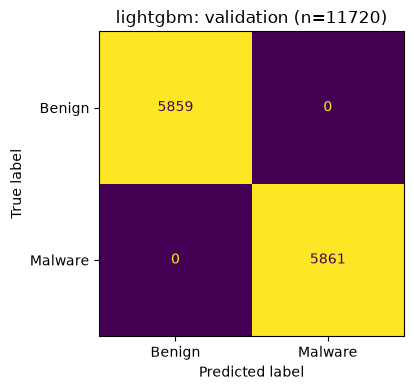

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, colorbar=False)
ax.set_title(f'{ALGORITHM}: validation (n={len(y_val)})')
fig.tight_layout()
plt.show()

## 5. Khảo sát ngưỡng từ chối (tau)
Mẫu có `p_max < tau` bị coi là `Uncertain`. Coverage = số mẫu được nhận / tổng. **Chưa chọn tau**; confidence chưa calibrated.

In [9]:
def coverage_at(tau, scores, correct):
    """Coverage và accuracy trên các mẫu được nhận (p_max >= tau)."""
    if not np.isfinite(tau) or not 0 <= tau <= 1:
        raise ValueError('tau phải hữu hạn trong [0,1]')
    accepted = scores >= tau
    count    = int(accepted.sum())
    return {
        'tau':               float(tau),
        'accepted':          count,
        'coverage':          count / len(scores),
        'accepted_accuracy': float(correct[accepted].mean()) if count else None,
    }

# Test nhanh cho hàm
assert coverage_at(.65, np.array([.65]), np.array([True]))['accepted'] == 1
assert coverage_at(1.,  np.array([.8]),  np.array([True]))['accepted_accuracy'] is None
for invalid in [-.1, 1.1, np.nan]:
    try:
        coverage_at(invalid, np.array([.8]), np.array([True]))
    except ValueError:
        pass
    else:
        raise AssertionError('Invalid tau accepted')

confidence       = probabilities.max(axis=1)
correct          = y_val.to_numpy() == predicted
coverage_results = [coverage_at(t, confidence, correct) for t in protocol['tau_grid']]
curve            = pd.DataFrame(coverage_results)

### 🔎 Xem: bảng coverage – accuracy theo tau

In [10]:
print(curve.to_string(index=False))

 tau  accepted  coverage  accepted_accuracy
0.00     11720  1.000000                1.0
0.50     11720  1.000000                1.0
0.60     11720  1.000000                1.0
0.65     11720  1.000000                1.0
0.70     11720  1.000000                1.0
0.80     11720  1.000000                1.0
0.90     11720  1.000000                1.0
0.95     11720  1.000000                1.0
0.99     11717  0.999744                1.0
1.00         0  0.000000                NaN


### 🔎 Xem: biểu đồ coverage – accuracy (đồng thời lưu vào run_dir)

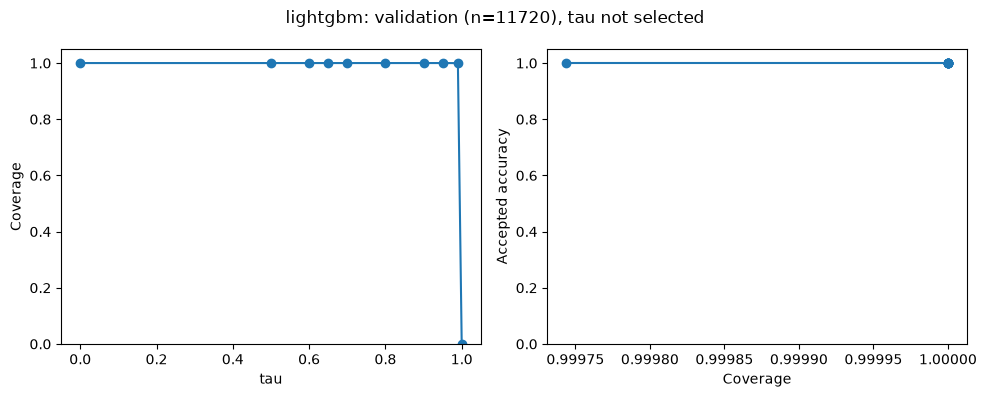

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(curve.tau, curve.coverage, marker='o')
axes[0].set(xlabel='tau', ylabel='Coverage', ylim=(0, 1.05))
axes[1].plot(curve.coverage, curve.accepted_accuracy, marker='o')
axes[1].set(xlabel='Coverage', ylabel='Accepted accuracy', ylim=(0, 1.05))
fig.suptitle(f'{ALGORITHM}: validation (n={len(y_val)}), tau not selected')
fig.tight_layout()
fig.savefig(run_dir / 'coverage_accuracy_curve.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. Lưu artifacts + kiểm tra reload
Lưu predictions, feature importance, model (`.joblib`), rồi nạp lại ở tiến trình mới để chắc chắn kết quả giống hệt.

In [12]:
# Feature importance (global; CSV lưu đủ tất cả feature)
importance = (
    pd.DataFrame({'feature': features, 'importance': pipeline['classifier'].feature_importances_})
    .sort_values('importance', ascending=False, kind='stable')
)

# Predictions: nhãn thật, nhãn dự đoán, điểm từng lớp
predictions = pd.DataFrame({'row_index': X_val.index, 'actual': y_val.to_numpy(), 'predicted': predicted})
for i, label in enumerate(classes):
    predictions['score_' + label] = probabilities[:, i]

predictions.to_csv(run_dir / 'validation_predictions.csv', index=False)
importance.to_csv(run_dir / 'validation_feature_importance.csv', index=False)

# Lưu cả Pipeline (candidate - chưa chọn model/tau)
model_path = run_dir / 'candidate_pipeline.joblib'
joblib.dump(pipeline, model_path)

['E:\\STUDYCLASS\\PYTHON\\reports\\evaluation\\binary\\lightgbm\\20261110T023844Z_c6cc41c1\\candidate_pipeline.joblib']

In [13]:
# Nạp lại model ở tiến trình Python MỚI, so xác suất trên 32 mẫu (không fit lại)
RELOAD_CODE = """
import json, sys
from pathlib import Path
import joblib, pandas as pd

root, model_path = map(Path, sys.argv[1:])
sys.path.insert(0, str(root))
model  = joblib.load(model_path)
sample = json.load(sys.stdin)
frame  = pd.DataFrame(sample['data'], columns=sample['columns'])
assert list(frame.columns) == list(model.feature_names_in_)
json.dump(model.predict_proba(frame).tolist(), sys.stdout, allow_nan=False)
"""

reload_sample  = X_val.iloc[:32]
reload_process = subprocess.run(
    [sys.executable, '-c', RELOAD_CODE, str(ROOT), str(model_path)],
    input=json.dumps({'data': reload_sample.to_numpy().tolist(), 'columns': features}, allow_nan=False),
    cwd=ROOT, capture_output=True, text=True, check=True, timeout=60,
)
reload_scores   = np.asarray(json.loads(reload_process.stdout))
expected_scores = probabilities[:len(reload_sample)]
assert reload_scores.shape == expected_scores.shape
np.testing.assert_allclose(reload_scores, expected_scores, rtol=0, atol=1e-12)
reload_max_error = float(np.max(np.abs(reload_scores - expected_scores)))

In [14]:
# Phiên bản thư viện
versions = {'python': platform.python_version()}
for pkg in ['numpy', 'pandas', 'scikit-learn', 'joblib', 'matplotlib', 'lightgbm']:
    try:
        versions[pkg] = metadata.version(pkg)
    except metadata.PackageNotFoundError:
        versions[pkg] = None

result = {
    **config,
    'status':    'completed',
    'run_id':    run_id,
    'rows':      {'train': len(X_train), 'validation': len(X_val)},
    'classes':   classes,
    'features':  features,
    'metrics':   metrics,
    'classification_report':  report,
    'confusion_matrix':       {'labels': classes, 'counts': cm.tolist()},
    'coverage_accuracy':      coverage_results,
    'train_seconds':          train_seconds,
    'validation_predict_proba_seconds': validation_seconds,
    'model_bytes':    model_path.stat().st_size,
    'model_sha256':   checksum(model_path),
    'selected_model': None,
    'selected_tau':   None,
    'test_evaluated': False,
    'reload_new_process_parity': True,
    'reload_check': {
        'status':                         'PASS',
        'sample_count':                   len(reload_sample),
        'max_absolute_probability_error': reload_max_error,
    },
    'versions': versions,
}
(run_dir / 'validation_metrics.json').write_text(json.dumps(result, indent=2, allow_nan=False), encoding='utf-8')

# Checksum toàn bộ file trong run
manifest = {p.name: checksum(p) for p in run_dir.iterdir() if p.is_file()}
(run_dir / 'checksums.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')

591

### 🔎 Xem: Top-10 feature importance (split count (LightGBM) - khác đơn vị với RF)
Đây là importance **toàn cục**, không phải giải thích cho từng mẫu.

In [15]:
print(importance.head(10).to_string(index=False))

                     feature  importance
handles.avg_handles_per_proc         341
        callbacks.ncallbacks         172
              handles.nevent         163
             handles.nthread         161
         pslist.avg_handlers         139
  ldrmodules.not_in_init_avg         135
        malfind.commitCharge         124
             handles.nmutant         121
              handles.ntimer         117
  ldrmodules.not_in_load_avg         111


### 🔎 Xem: tổng kết (SYNC RESULT)

In [16]:
print('SYNC RESULT - PHASE 4 candidate:', ALGORITHM)
print('Validation:', metrics)
print('Artifacts:', run_dir)
print(f'Reload parity PASS: {len(reload_sample)} samples, max abs error={reload_max_error:.3g}')
print('selected_model/tau=None; test_evaluated=False')

SYNC RESULT - PHASE 4 candidate: lightgbm
Validation: {'accuracy': 1.0, 'macro_f1': 1.0, 'weighted_f1': 1.0, 'macro_recall': 1.0}
Artifacts: E:\STUDYCLASS\PYTHON\reports\evaluation\binary\lightgbm\20261110T023844Z_c6cc41c1
Reload parity PASS: 32 samples, max abs error=0
selected_model/tau=None; test_evaluated=False


## 7. Bước tiếp theo
Đọc kỹ kết quả ở các cell 🔎 (lớp nào hay nhầm, feature nào quan trọng có thể là artifact thu thập dữ liệu không). Chốt model/tau bằng validation, ghi lại quyết định riêng, rồi mới đánh giá test ở phase sau. Notebook này **cố ý không có cell test**.

In [ ]:
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

TASK = "binary"       # Notebook 04: đổi thành "multiclass"
RUN_FINAL_TEST = True  # Đổi thành True khi sẵn sàng chạy cell này

if RUN_FINAL_TEST:
    root = Path.cwd().resolve()
    if not (root / "preprocessing.py").is_file():
        root = root.parent
    if not (root / "preprocessing.py").is_file():
        raise RuntimeError("Mở notebook từ project root hoặc notebooks/.")

    sys.path.insert(0, str(root))
    from preprocessing import checksum, load_splits

    decision = json.loads(
        (root / "configs/operating_threshold.json").read_text(encoding="utf-8-sig")
    )
    assert decision["model_selection_status"] == "locked"
    tau = decision["tau"]
    chosen = decision["selected_models"][TASK]

    model_path = root / chosen["pipeline_path"]
    assert checksum(model_path) == chosen["pipeline_sha256"]
    assert checksum(root / "data/splits/master_split.csv") == decision["split_sha256"]

    out = root / "reports/final_test" / TASK / chosen["run_id"]
    if out.exists():
        raise FileExistsError(f"Đã có thư mục kết quả: {out}")

    pipeline = joblib.load(model_path)
    X_test, y_test = load_splits(TASK)["test"]
    classes = pipeline.classes_.tolist()
    assert classes == chosen["classes"]
    assert list(X_test.columns) == list(pipeline.feature_names_in_)

    probabilities = pipeline.predict_proba(X_test)
    scores = probabilities.max(axis=1)
    predicted = np.asarray(classes)[probabilities.argmax(axis=1)]
    actual = y_test.to_numpy()
    correct = predicted == actual
    accepted = scores >= tau

    report = classification_report(
        actual, predicted, labels=classes, output_dict=True, zero_division=0
    )
    by_class = {}
    for label in classes:
        in_class = actual == label
        received = in_class & accepted
        by_class[label] = {
            "support": int(in_class.sum()),
            "accepted": int(received.sum()),
            "coverage": float(accepted[in_class].mean()) if in_class.any() else None,
            "accepted_accuracy": float(correct[received].mean()) if received.any() else None,
        }

    results = {
        "split": "test",
        "task": TASK,
        "model": chosen["algorithm"],
        "run_id": chosen["run_id"],
        "pipeline_sha256": chosen["pipeline_sha256"],
        "split_sha256": decision["split_sha256"],
        "tau": tau,
        "samples": len(actual),
        "accuracy": accuracy_score(actual, predicted),
        "macro_f1": report["macro avg"]["f1-score"],
        "classification_report": report,
        "confusion_matrix": {
            "labels": classes,
            "counts": confusion_matrix(actual, predicted, labels=classes).tolist(),
        },
        "accepted": int(accepted.sum()),
        "uncertain": int((~accepted).sum()),
        "coverage": float(accepted.mean()),
        "accepted_accuracy": float(correct[accepted].mean()) if accepted.any() else None,
        "coverage_by_true_class": by_class,
    }

    predictions = pd.DataFrame({
        "row_index": X_test.index,
        "actual": actual,
        "predicted": predicted,
        "max_score": scores,
        "accepted": accepted,
        "decision": np.where(accepted, predicted, decision["rejection_label"]),
    })
    for i, label in enumerate(classes):
        predictions[f"score_{label}"] = probabilities[:, i]

    out.mkdir(parents=True, exist_ok=False)
    predictions.to_csv(out / "test_predictions.csv", index=False)
    (out / "test_metrics.json").write_text(
        json.dumps(results, indent=2, ensure_ascii=False, allow_nan=False),
        encoding="utf-8",
    )

    print(f"{TASK} | LightGBM | test n={len(actual)} | tau={tau}")
    print(f"Accuracy={results['accuracy']:.4%} | Macro-F1={results['macro_f1']:.6f}")
    print(f"Coverage={results['coverage']:.4%} | Uncertain={results['uncertain']}")
    acc = results["accepted_accuracy"]
    print("Accepted accuracy =", f"{acc:.4%}" if acc is not None else "N/A")
    print(pd.DataFrame(by_class).T)
    print("Artifacts:", out)
else:
    print("Final test đang tắt. Đặt RUN_FINAL_TEST = True để chạy.")

Final test đang tắt. Đặt RUN_FINAL_TEST = True để chạy.
